In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10,6)
pd.set_option('display.max_columns', None)

In [6]:
brca = pd.read_csv('../data/brca.csv')

In [7]:
brca.head()
brca.info()
brca.shape

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           569 non-null    int64  
 1   x.radius_mean        569 non-null    float64
 2   x.texture_mean       569 non-null    float64
 3   x.perimeter_mean     569 non-null    float64
 4   x.area_mean          569 non-null    float64
 5   x.smoothness_mean    569 non-null    float64
 6   x.compactness_mean   569 non-null    float64
 7   x.concavity_mean     569 non-null    float64
 8   x.concave_pts_mean   569 non-null    float64
 9   x.symmetry_mean      569 non-null    float64
 10  x.fractal_dim_mean   569 non-null    float64
 11  x.radius_se          569 non-null    float64
 12  x.texture_se         569 non-null    float64
 13  x.perimeter_se       569 non-null    float64
 14  x.area_se            569 non-null    float64
 15  x.smoothness_se      569 non-null    float64
 16  x

(569, 32)

In [8]:
brca.describe()

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,x.fractal_dim_mean,x.radius_se,x.texture_se,x.perimeter_se,x.area_se,x.smoothness_se,x.compactness_se,x.concavity_se,x.concave_pts_se,x.symmetry_se,x.fractal_dim_se,x.radius_worst,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,285.000000,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,164.400426,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,1.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,143.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,285.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,427.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,569.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [9]:
brca = brca.drop(columns=[c for c in brca.columns if 'Unnamed' in c], errors='ignore')

In [10]:
brca.columns

Index(['x.radius_mean', 'x.texture_mean', 'x.perimeter_mean', 'x.area_mean',
       'x.smoothness_mean', 'x.compactness_mean', 'x.concavity_mean',
       'x.concave_pts_mean', 'x.symmetry_mean', 'x.fractal_dim_mean',
       'x.radius_se', 'x.texture_se', 'x.perimeter_se', 'x.area_se',
       'x.smoothness_se', 'x.compactness_se', 'x.concavity_se',
       'x.concave_pts_se', 'x.symmetry_se', 'x.fractal_dim_se',
       'x.radius_worst', 'x.texture_worst', 'x.perimeter_worst',
       'x.area_worst', 'x.smoothness_worst', 'x.compactness_worst',
       'x.concavity_worst', 'x.concave_pts_worst', 'x.symmetry_worst',
       'x.fractal_dim_worst', 'y'],
      dtype='str')

In [11]:
brca.info()
brca.isnull().sum().sort_values(ascending= False).head()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   x.radius_mean        569 non-null    float64
 1   x.texture_mean       569 non-null    float64
 2   x.perimeter_mean     569 non-null    float64
 3   x.area_mean          569 non-null    float64
 4   x.smoothness_mean    569 non-null    float64
 5   x.compactness_mean   569 non-null    float64
 6   x.concavity_mean     569 non-null    float64
 7   x.concave_pts_mean   569 non-null    float64
 8   x.symmetry_mean      569 non-null    float64
 9   x.fractal_dim_mean   569 non-null    float64
 10  x.radius_se          569 non-null    float64
 11  x.texture_se         569 non-null    float64
 12  x.perimeter_se       569 non-null    float64
 13  x.area_se            569 non-null    float64
 14  x.smoothness_se      569 non-null    float64
 15  x.compactness_se     569 non-null    float64
 16  x

x.radius_mean        0
x.texture_mean       0
x.perimeter_mean     0
x.area_mean          0
x.smoothness_mean    0
dtype: int64

In [12]:
brca['y'].value_counts()
brca['y'].unique()

<StringArray>
['B', 'M']
Length: 2, dtype: str

In [13]:
# Cell: rename columns to be human-friendly
brca.columns = [c.replace('x.', '') for c in brca.columns]
brca.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_pts_mean,symmetry_mean,fractal_dim_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_pts_se,symmetry_se,fractal_dim_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_pts_worst,symmetry_worst,fractal_dim_worst,y
0,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,0.05766,0.2699,0.7886,2.058,23.560,0.008462,0.014600,0.02387,0.013150,0.01980,0.002300,15.110,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,0.06811,0.1852,0.7477,1.383,14.670,0.004097,0.018980,0.01698,0.006490,0.01678,0.002425,14.500,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,0.06905,0.2773,0.9768,1.909,15.700,0.009606,0.014320,0.01985,0.014210,0.02027,0.002968,10.230,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,0.05863,0.1839,2.3420,1.170,14.160,0.004352,0.004899,0.01343,0.011640,0.02671,0.001777,13.300,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,0.06503,0.1563,0.9567,1.094,8.205,0.008968,0.016460,0.01588,0.005917,0.02574,0.002582,8.964,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


In [14]:
# Cell: encode target
brca['y'] = brca['y'].map({'M': 1, 'B': 0})   # adjust if labels differ
brca['y'].value_counts()

y
0    357
1    212
Name: count, dtype: int64

In [15]:
# Cell: verify
brca.info()
brca.isnull().sum().sum()   # should be 0

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   radius_mean        569 non-null    float64
 1   texture_mean       569 non-null    float64
 2   perimeter_mean     569 non-null    float64
 3   area_mean          569 non-null    float64
 4   smoothness_mean    569 non-null    float64
 5   compactness_mean   569 non-null    float64
 6   concavity_mean     569 non-null    float64
 7   concave_pts_mean   569 non-null    float64
 8   symmetry_mean      569 non-null    float64
 9   fractal_dim_mean   569 non-null    float64
 10  radius_se          569 non-null    float64
 11  texture_se         569 non-null    float64
 12  perimeter_se       569 non-null    float64
 13  area_se            569 non-null    float64
 14  smoothness_se      569 non-null    float64
 15  compactness_se     569 non-null    float64
 16  concavity_se       569 non-null    fl

np.int64(0)

In [16]:
brca = brca.rename(columns={'y': 'diagnosis'})

In [17]:
print(brca['diagnosis'].value_counts(normalize=True).round(3))

diagnosis
0    0.627
1    0.373
Name: proportion, dtype: float64


In [18]:
brca.duplicated().sum()

np.int64(0)

In [19]:
brca = brca.rename(columns={'y': 'diagnosis'})

brca['diagnosis_label'] = brca['diagnosis'].map({0: 'Benign', 1: 'Malignant'})

brca[['diagnosis', 'diagnosis_label']].head()

,diagnosis,diagnosis_label
0,0,Benign
1,0,Benign
2,0,Benign
3,0,Benign
4,0,Benign


In [20]:
brca['diagnosis_label'].value_counts()

diagnosis_label
Benign       357
Malignant    212
Name: count, dtype: int64

In [21]:
import math

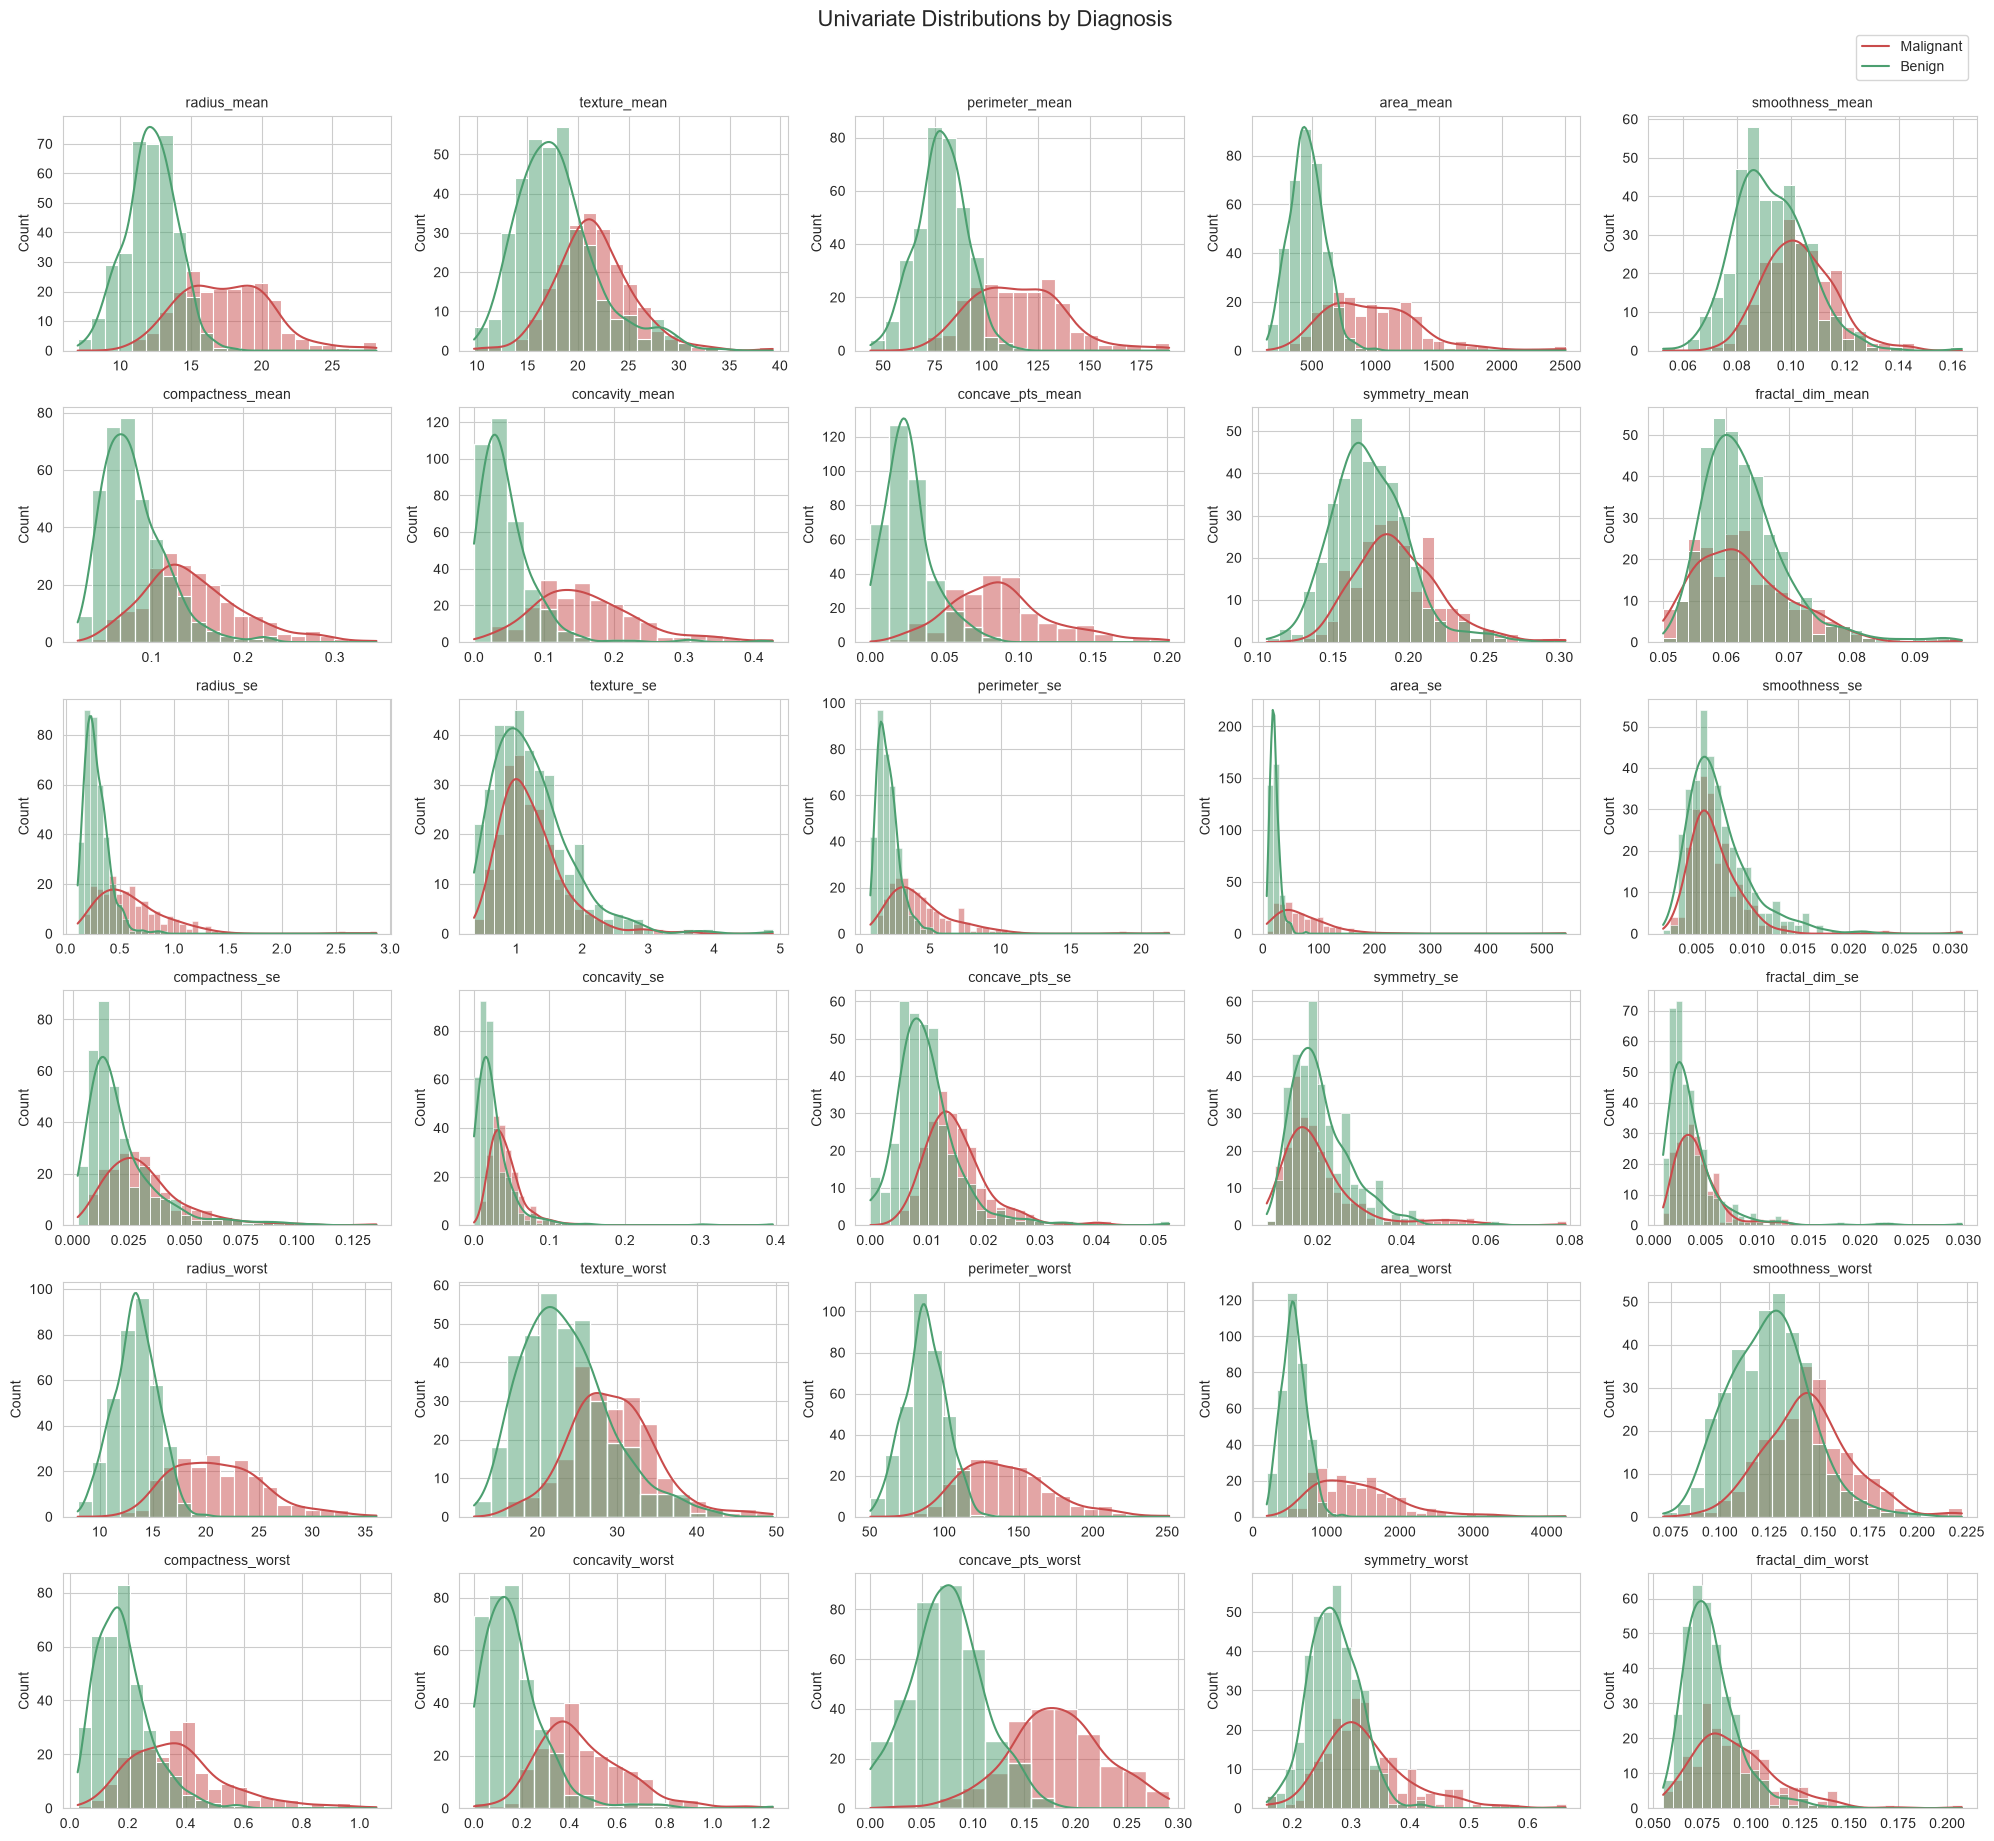

In [38]:
features = [c for c in brca.columns if c not in ['diagnosis', 'diagnosis_label']]
n_cols = 5
n_rows = math.ceil(len(features) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3))
axes = axes.flatten()

for i, feat in enumerate(features):
    sns.histplot(data=brca, x=feat, hue='diagnosis_label', kde=True,
                 ax=axes[i], palette={'Benign': '#4C9F70', 'Malignant': '#C94C4C'})
    axes[i].set_title(feat, fontsize=10)
    axes[i].set_xlabel('')
    if axes[i].legend_:
        axes[i].legend_.remove()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Univariate Distributions by Diagnosis', fontsize=16, y=1.02)
fig.legend(labels=['Malignant', 'Benign'], loc='upper right', bbox_to_anchor=(0.99, 1.01))
plt.tight_layout()
plt.savefig('../images/univariate_grid.png', dpi=150, bbox_inches='tight')  # saved to current folder
plt.show()

### Univariate Analysis Observations

- **Strong class separation** in size-related features (`radius_*`, `perimeter_*`, `area_*`) malignant tumors are consistently larger.
- **Shape-related features** (`concavity_*`, `concave_pts_*`, `compactness_*`) also separate well malignant tumors have more irregular borders.
- **Weak separation** in `smoothness_*`, `symmetry_*`, and especially `fractal_dim_*` these overlap heavily and are likely weak predictors.
- Most distributions are **right-skewed**, suggesting feature scaling (StandardScaler) will benefit the logistic regression model.
- The `_worst` features (coming next) typically show the strongest separation worth checking next.

In [23]:
brca.columns.tolist()

['radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave_pts_mean',
 'symmetry_mean',
 'fractal_dim_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave_pts_se',
 'symmetry_se',
 'fractal_dim_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave_pts_worst',
 'symmetry_worst',
 'fractal_dim_worst',
 'diagnosis',
 'diagnosis_label']

In [24]:
worst_features = [c for c in brca.columns if 'worst' in c]
print(worst_features)

['radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_pts_worst', 'symmetry_worst', 'fractal_dim_worst']


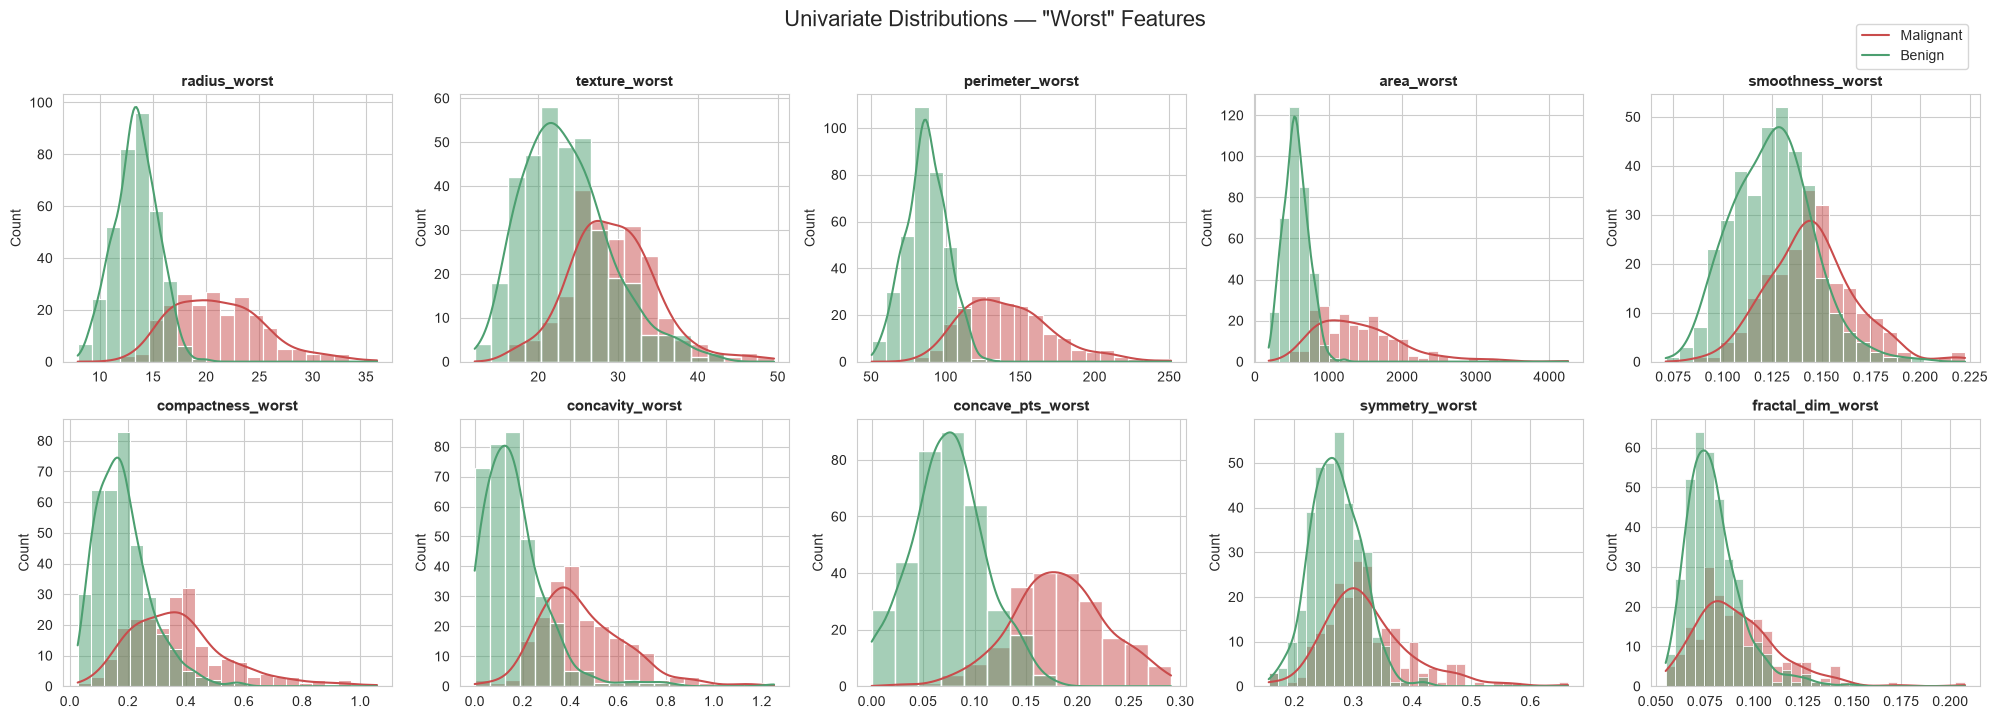

In [25]:
n_cols = 5
n_rows = math.ceil(len(worst_features) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, feat in enumerate(worst_features):
    sns.histplot(data=brca, x=feat, hue='diagnosis_label', kde=True,
                 ax=axes[i], palette={'Benign': '#4C9F70', 'Malignant': '#C94C4C'})
    axes[i].set_title(feat, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    if axes[i].legend_:
        axes[i].legend_.remove()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Univariate Distributions — "Worst" Features', fontsize=16, y=1.02)
fig.legend(labels=['Malignant', 'Benign'], loc='upper right', bbox_to_anchor=(0.99, 1.01))
plt.tight_layout()
plt.savefig('../images/univariate_worst.png', dpi=150, bbox_inches='tight')
plt.show()

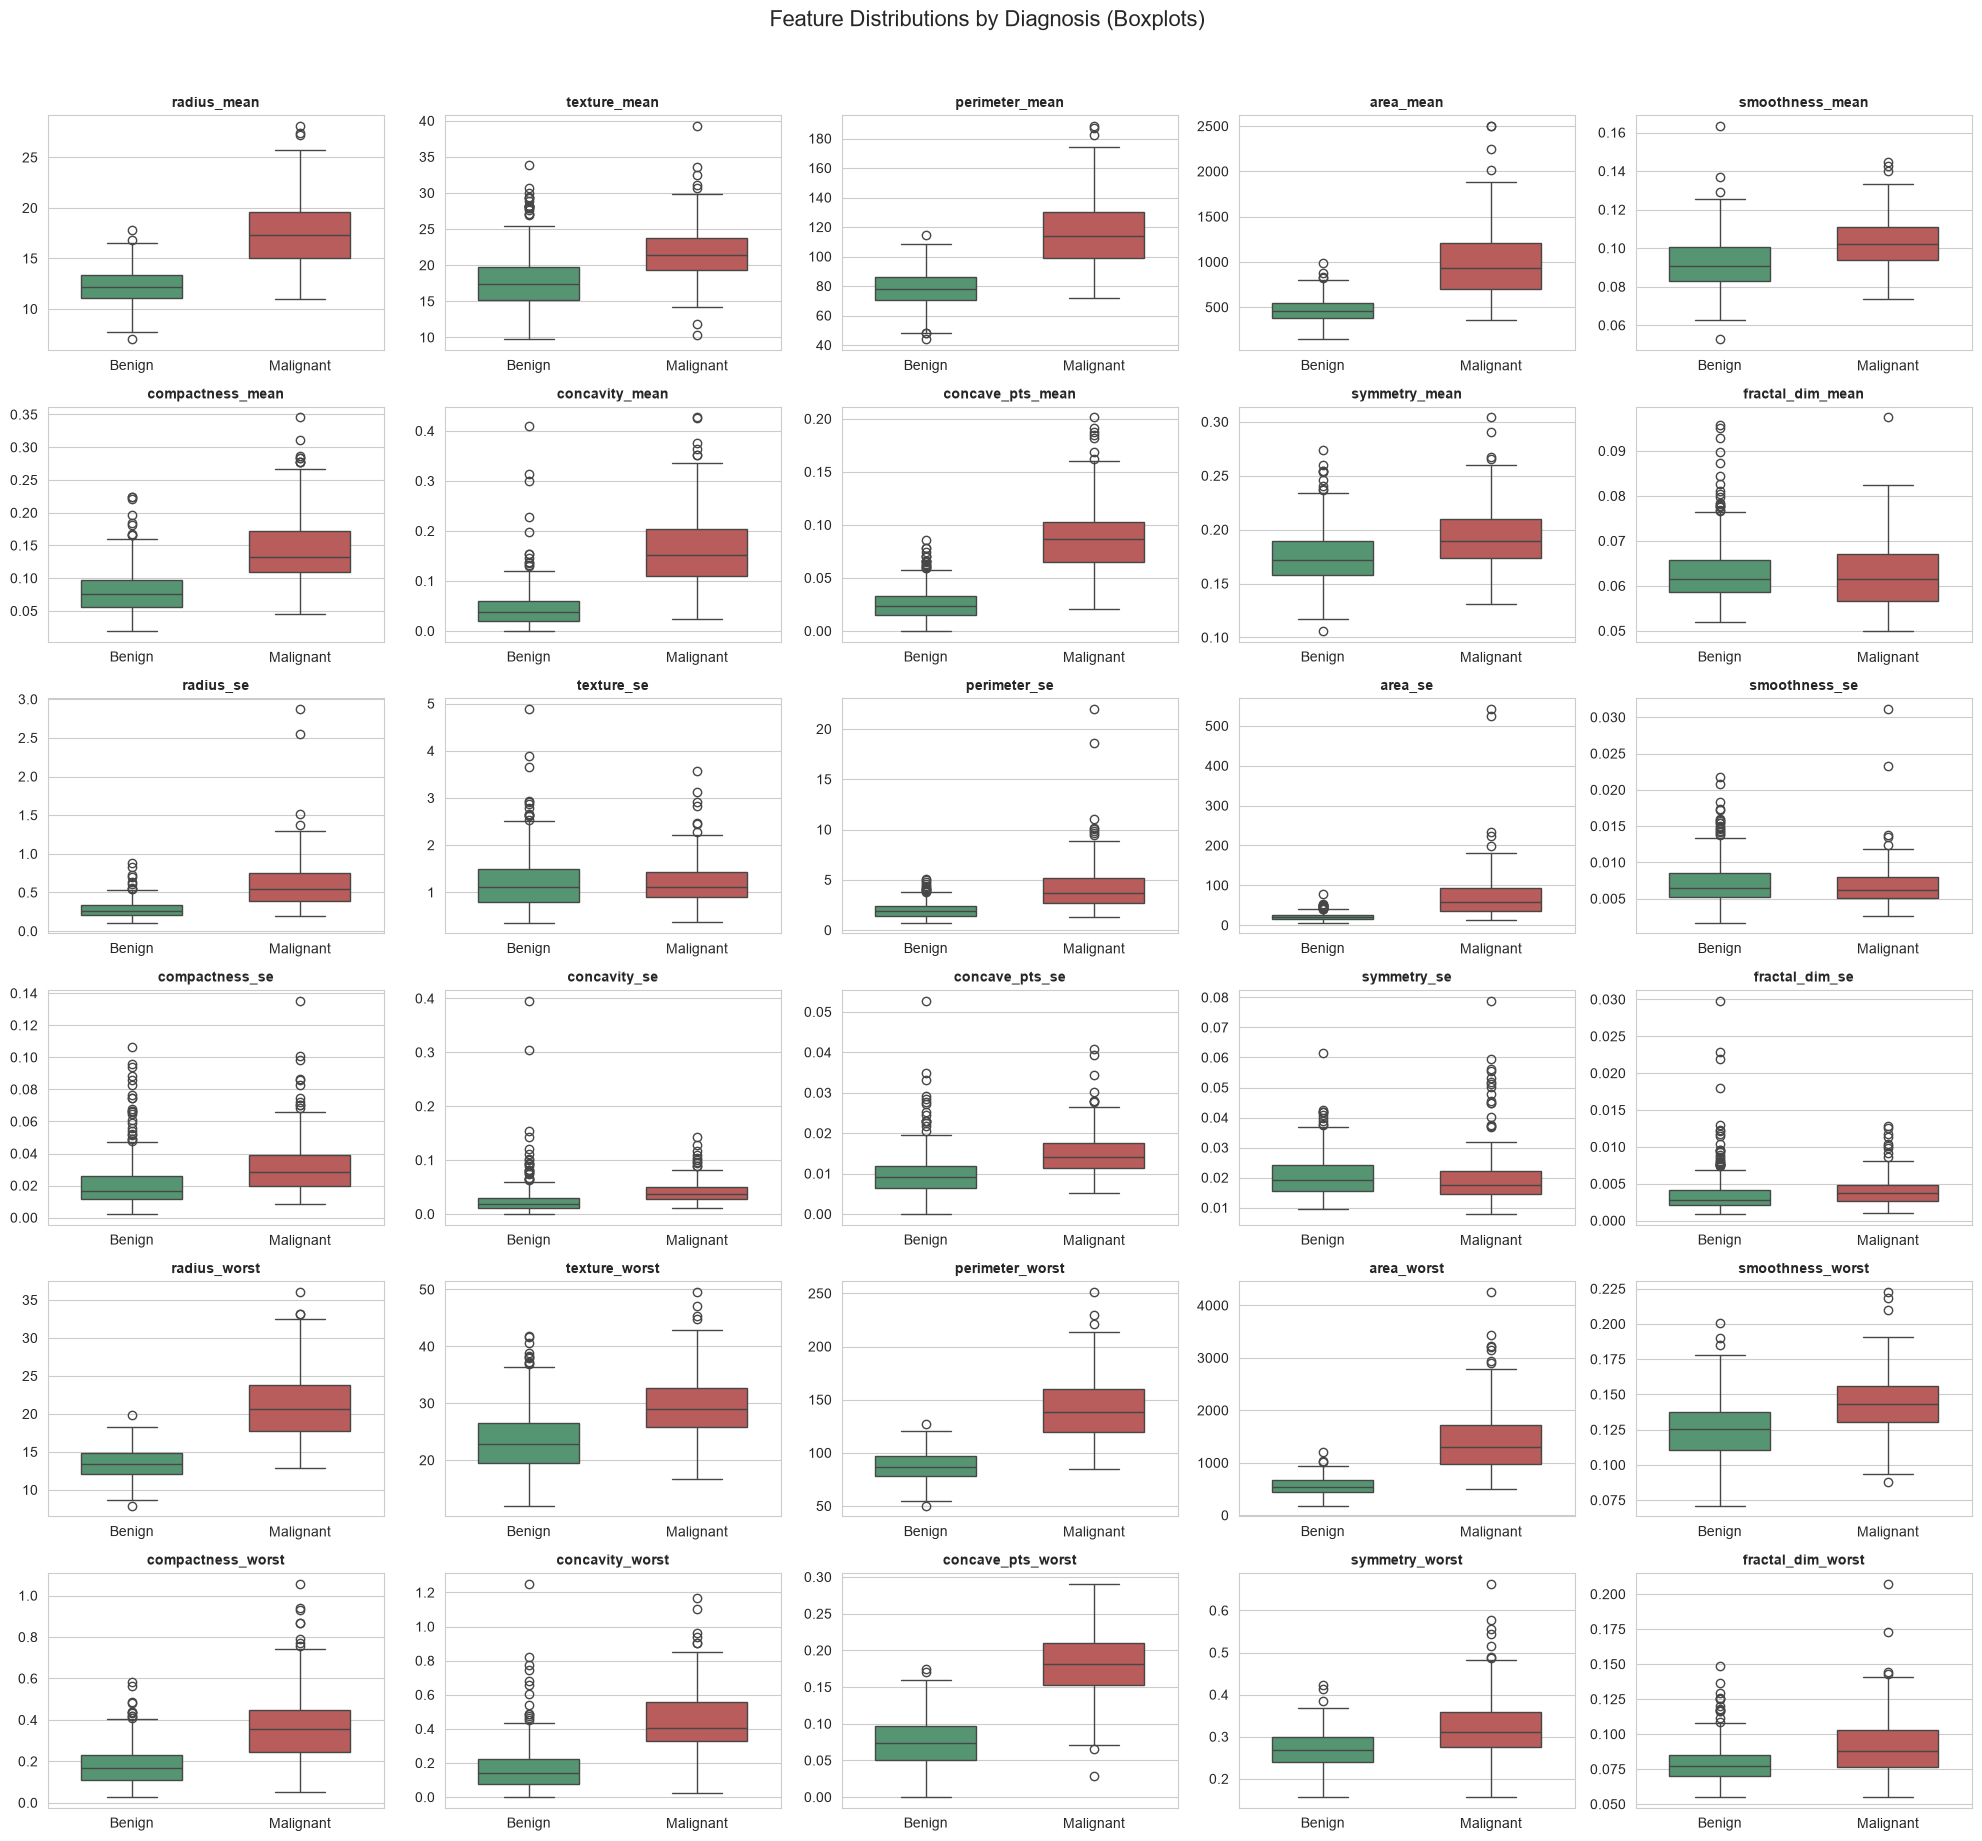

In [39]:
features = [c for c in brca.columns if c not in ['diagnosis', 'diagnosis_label']]
n_cols = 5
n_rows = math.ceil(len(features) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3))
axes = axes.flatten()

for i, feat in enumerate(features):
    sns.boxplot(data=brca, x='diagnosis_label', y=feat, ax=axes[i],
                palette={'Benign': '#4C9F70', 'Malignant': '#C94C4C'},
                hue='diagnosis_label', legend=False, width=0.6)
    axes[i].set_title(feat, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Feature Distributions by Diagnosis (Boxplots)', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('../images/boxplots_all.png', dpi=150, bbox_inches='tight')
plt.show()

In [27]:
summary = brca.groupby('diagnosis_label')[features].mean().T
summary['diff'] = (summary['Malignant'] - summary['Benign']).abs()
summary['pct_diff'] = (summary['diff'] / summary['Benign'].abs()) * 100
summary = summary.sort_values('pct_diff', ascending=False)
summary.head(10).round(2)

diagnosis_label,Benign,Malignant,diff,pct_diff
concavity_mean,0.05,0.16,0.11,249.07
area_se,21.14,72.67,51.54,243.85
concave_pts_mean,0.03,0.09,0.06,242.14
concavity_worst,0.17,0.45,0.28,171.06
area_worst,558.90,1422.29,863.39,154.48
concave_pts_worst,0.07,0.18,0.11,144.80
perimeter_se,2.00,4.32,2.32,116.16
radius_se,0.28,0.61,0.33,114.40
area_mean,462.79,978.38,515.59,111.41
compactness_worst,0.18,0.37,0.19,105.19


In [28]:
summary.head(15).round(2)

diagnosis_label,Benign,Malignant,diff,pct_diff
concavity_mean,0.05,0.16,0.11,249.07
area_se,21.14,72.67,51.54,243.85
concave_pts_mean,0.03,0.09,0.06,242.14
concavity_worst,0.17,0.45,0.28,171.06
area_worst,558.90,1422.29,863.39,154.48
concave_pts_worst,0.07,0.18,0.11,144.80
perimeter_se,2.00,4.32,2.32,116.16
radius_se,0.28,0.61,0.33,114.40
area_mean,462.79,978.38,515.59,111.41
compactness_worst,0.18,0.37,0.19,105.19


### Key Observation Bimodal Separation

The "worst" features (`radius_worst`, `perimeter_worst`, `area_worst`,
`concave_pts_worst`) show **strong bimodal separation** between Benign and
Malignant classes the distributions barely overlap. This confirms what the
`pct_diff` table shows numerically: size- and shape-related measurements of
the *largest* cell nuclei are the most discriminative.

By contrast, `smoothness_worst`, `symmetry_worst`, and `fractal_dim_worst`
show heavy overlap, suggesting they contribute little to class separation.

**Modeling implication:** `_worst` and `_mean` size/shape features should be
the strongest predictors in logistic regression, while `fractal_dim_*` and
`smoothness_*` features may be candidates for removal during feature selection.

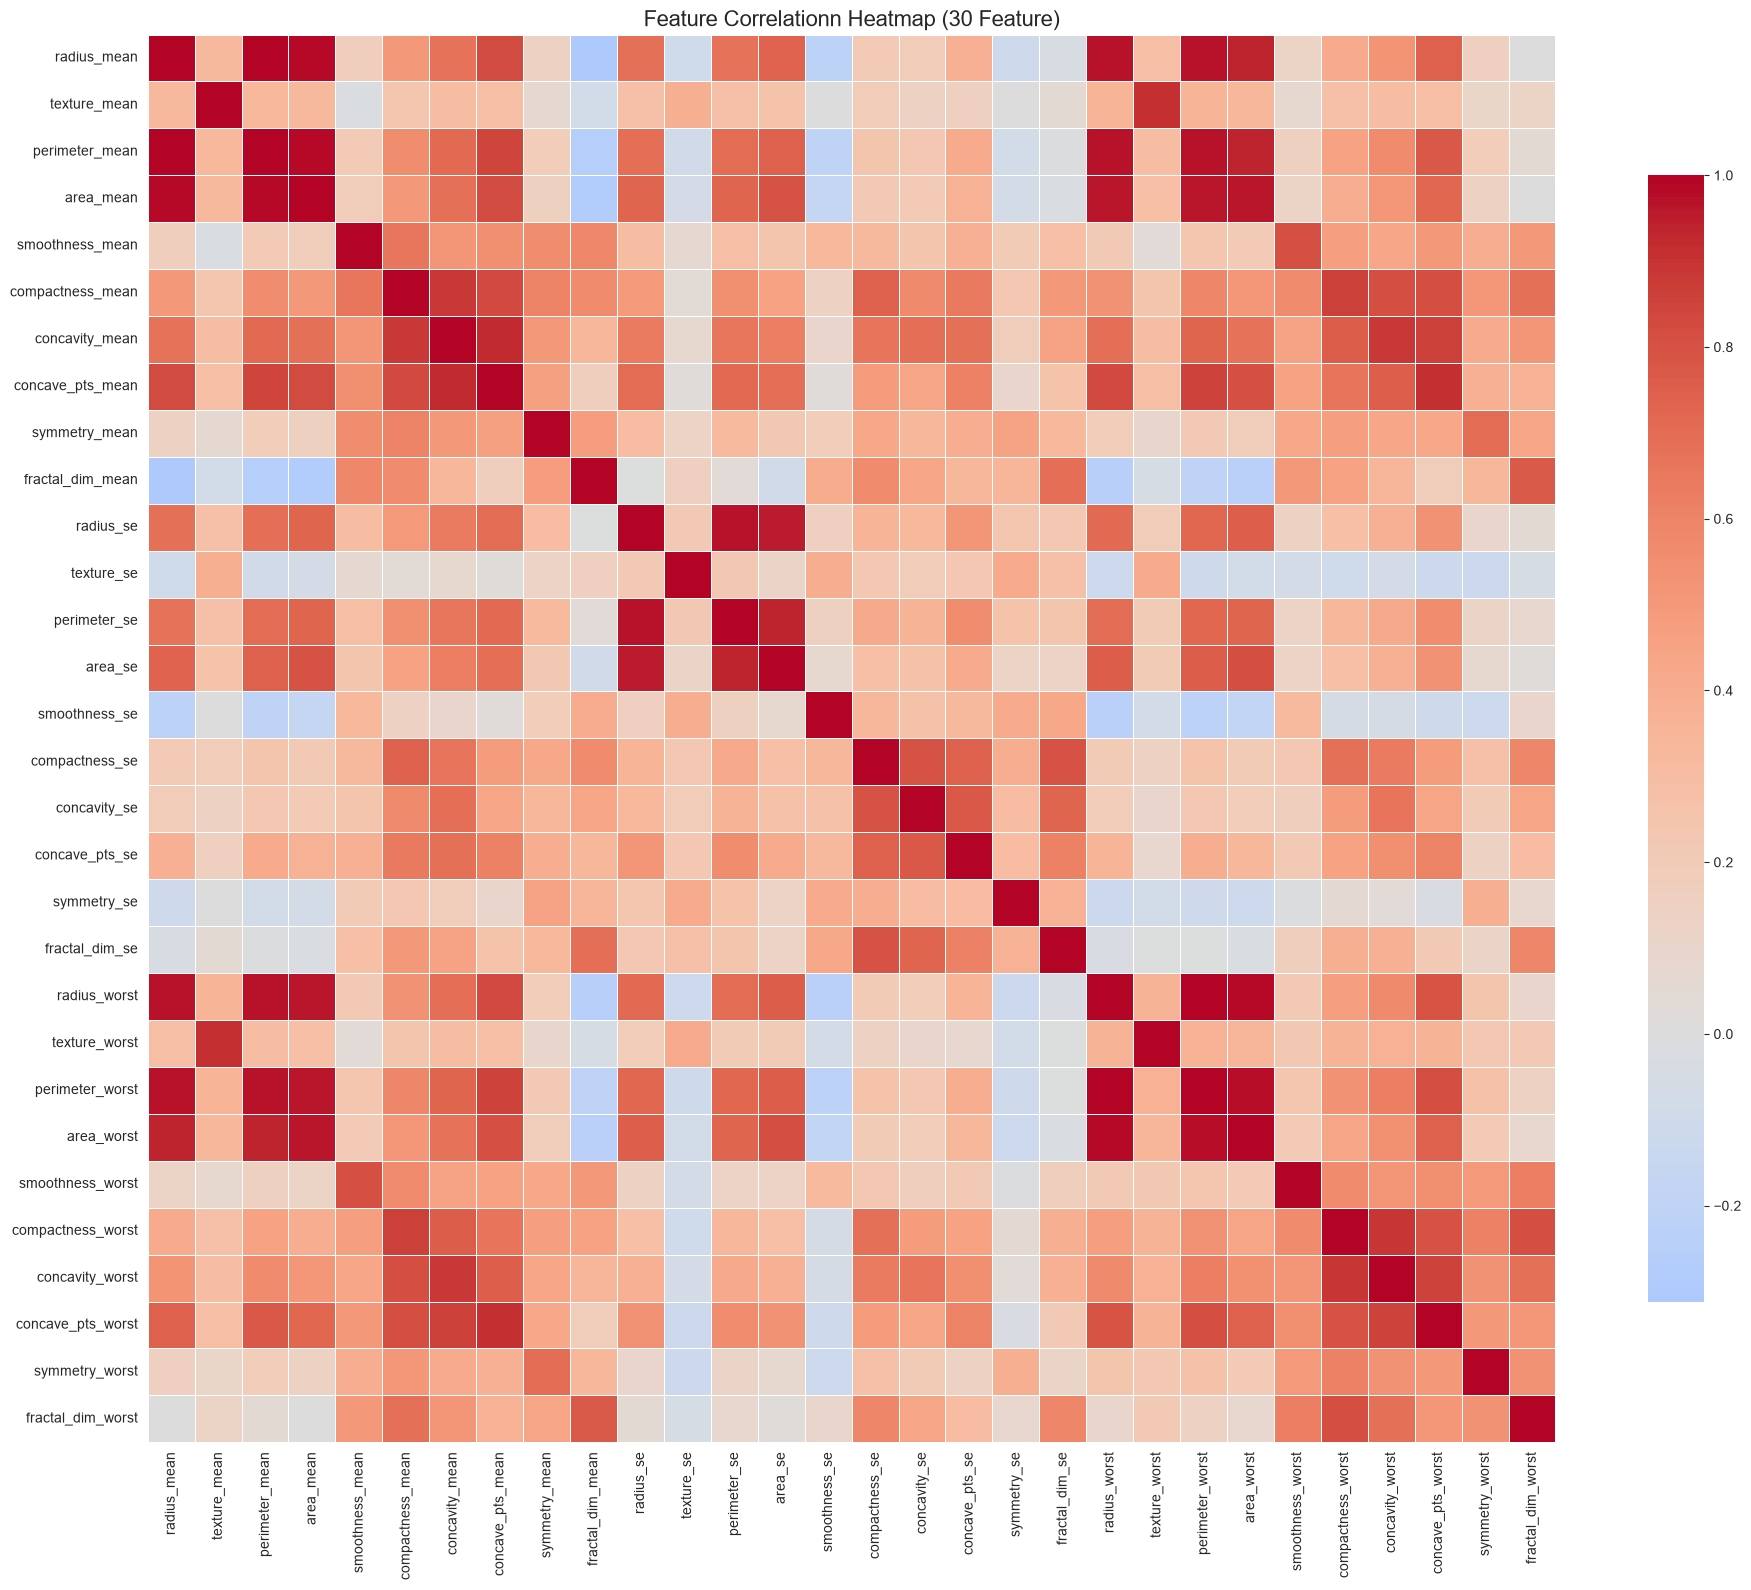

In [40]:
features = [c for c in brca.columns if c not in ['diagnosis', 'diagnosis_label']]

plt.figure(figsize=(20,16))
corr = brca[features].corr()

sns.heatmap(corr, cmap='coolwarm', center= 0, annot= False,
            square= True, linewidth= 0.5, cbar_kws= {'shrink':0.8})
plt.title('Feature Correlationn Heatmap (30 Feature)', fontsize= 16)
plt.tight_layout()
plt.savefig('../images/Correlation_heatmap.png',
            dpi=150, bbox_inches='tight')
plt.show()
        

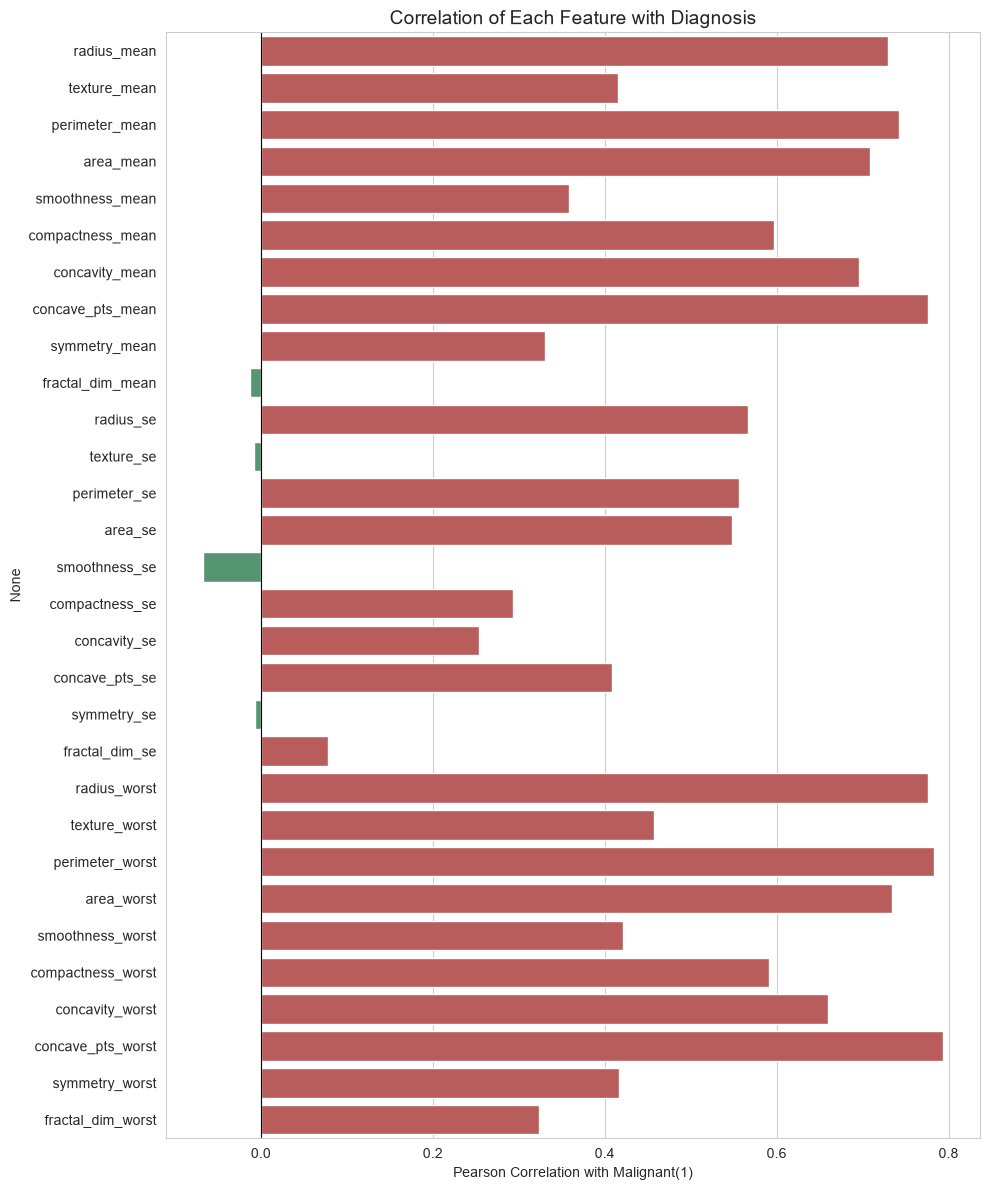

In [41]:
target_corr= brca[features +['diagnosis']].corr() ['diagnosis'].drop('diagnosis')
targer_corr= target_corr.sort_values(ascending =False)

plt.figure(figsize=(10,12))
colors = ['#C94C4C' if v > 0 else '#4C9F70' for v in  target_corr.values]
sns.barplot(x=target_corr.values, y=target_corr.index,hue=target_corr.index, palette=colors, legend=False)     
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of Each Feature with Diagnosis', fontsize=14)
plt.xlabel('Pearson Correlation with Malignant(1)')
plt.tight_layout()
plt.savefig('../images/target_correlation.png', dpi= 150, bbox_inches='tight')
plt.show()
    
          


In [31]:
corr_matrix = brca[features].corr().abs()

#take the upper triangleonly (avoid duplicate pairs)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape),
                                  k=1).astype(bool))
#flatten and sort
high_corr= upper.stack().sort_values(ascending=False).head(20)
high_corr= high_corr[high_corr > 0.9]

print ("Feature pairs with |r| > 0.9:")
print(high_corr.round(3))

Feature pairs with |r| > 0.9:
radius_mean      perimeter_mean      0.998
radius_worst     perimeter_worst     0.994
radius_mean      area_mean           0.987
perimeter_mean   area_mean           0.987
radius_worst     area_worst          0.984
perimeter_worst  area_worst          0.978
radius_se        perimeter_se        0.973
perimeter_mean   perimeter_worst     0.970
radius_mean      radius_worst        0.970
perimeter_mean   radius_worst        0.969
radius_mean      perimeter_worst     0.965
area_mean        radius_worst        0.963
                 area_worst          0.959
                 perimeter_worst     0.959
radius_se        area_se             0.952
perimeter_mean   area_worst          0.942
radius_mean      area_worst          0.941
perimeter_se     area_se             0.938
concavity_mean   concave_pts_mean    0.921
texture_mean     texture_worst       0.912
dtype: float64


### Correlation Analysis: Key Findings

1. **Severe multicollinearity in size features**: `radius`, `perimeter`, and
   `area` are correlated at |r| > 0.98 in their mean, se, and worst forms.
   These 9 features carry roughly the information of 3 a candidate for
   dimensionality reduction before modeling.

2. **Shape features cluster together**: `concavity`, `concave_pts`, and
   `compactness` are moderately-to-strongly correlated with each other,
   suggesting they measure overlapping aspects of tumor border irregularity.

3. **Strongest predictors of malignancy**: `concave_pts_worst`,
   `perimeter_worst`, `radius_worst`, `area_worst`, and `concave_pts_mean`
   all show |r| = 0.75–0.79 with the target the strongest single-feature
   correlations in the dataset.

4. **Weakest predictors**: `fractal_dim_*` and `symmetry_se` show |r| < 0.15
   with the target candidates for removal.

5. **No negatively correlated predictors of note**: all top features correlate
   positively with malignancy larger, more irregular tumors = malignant.

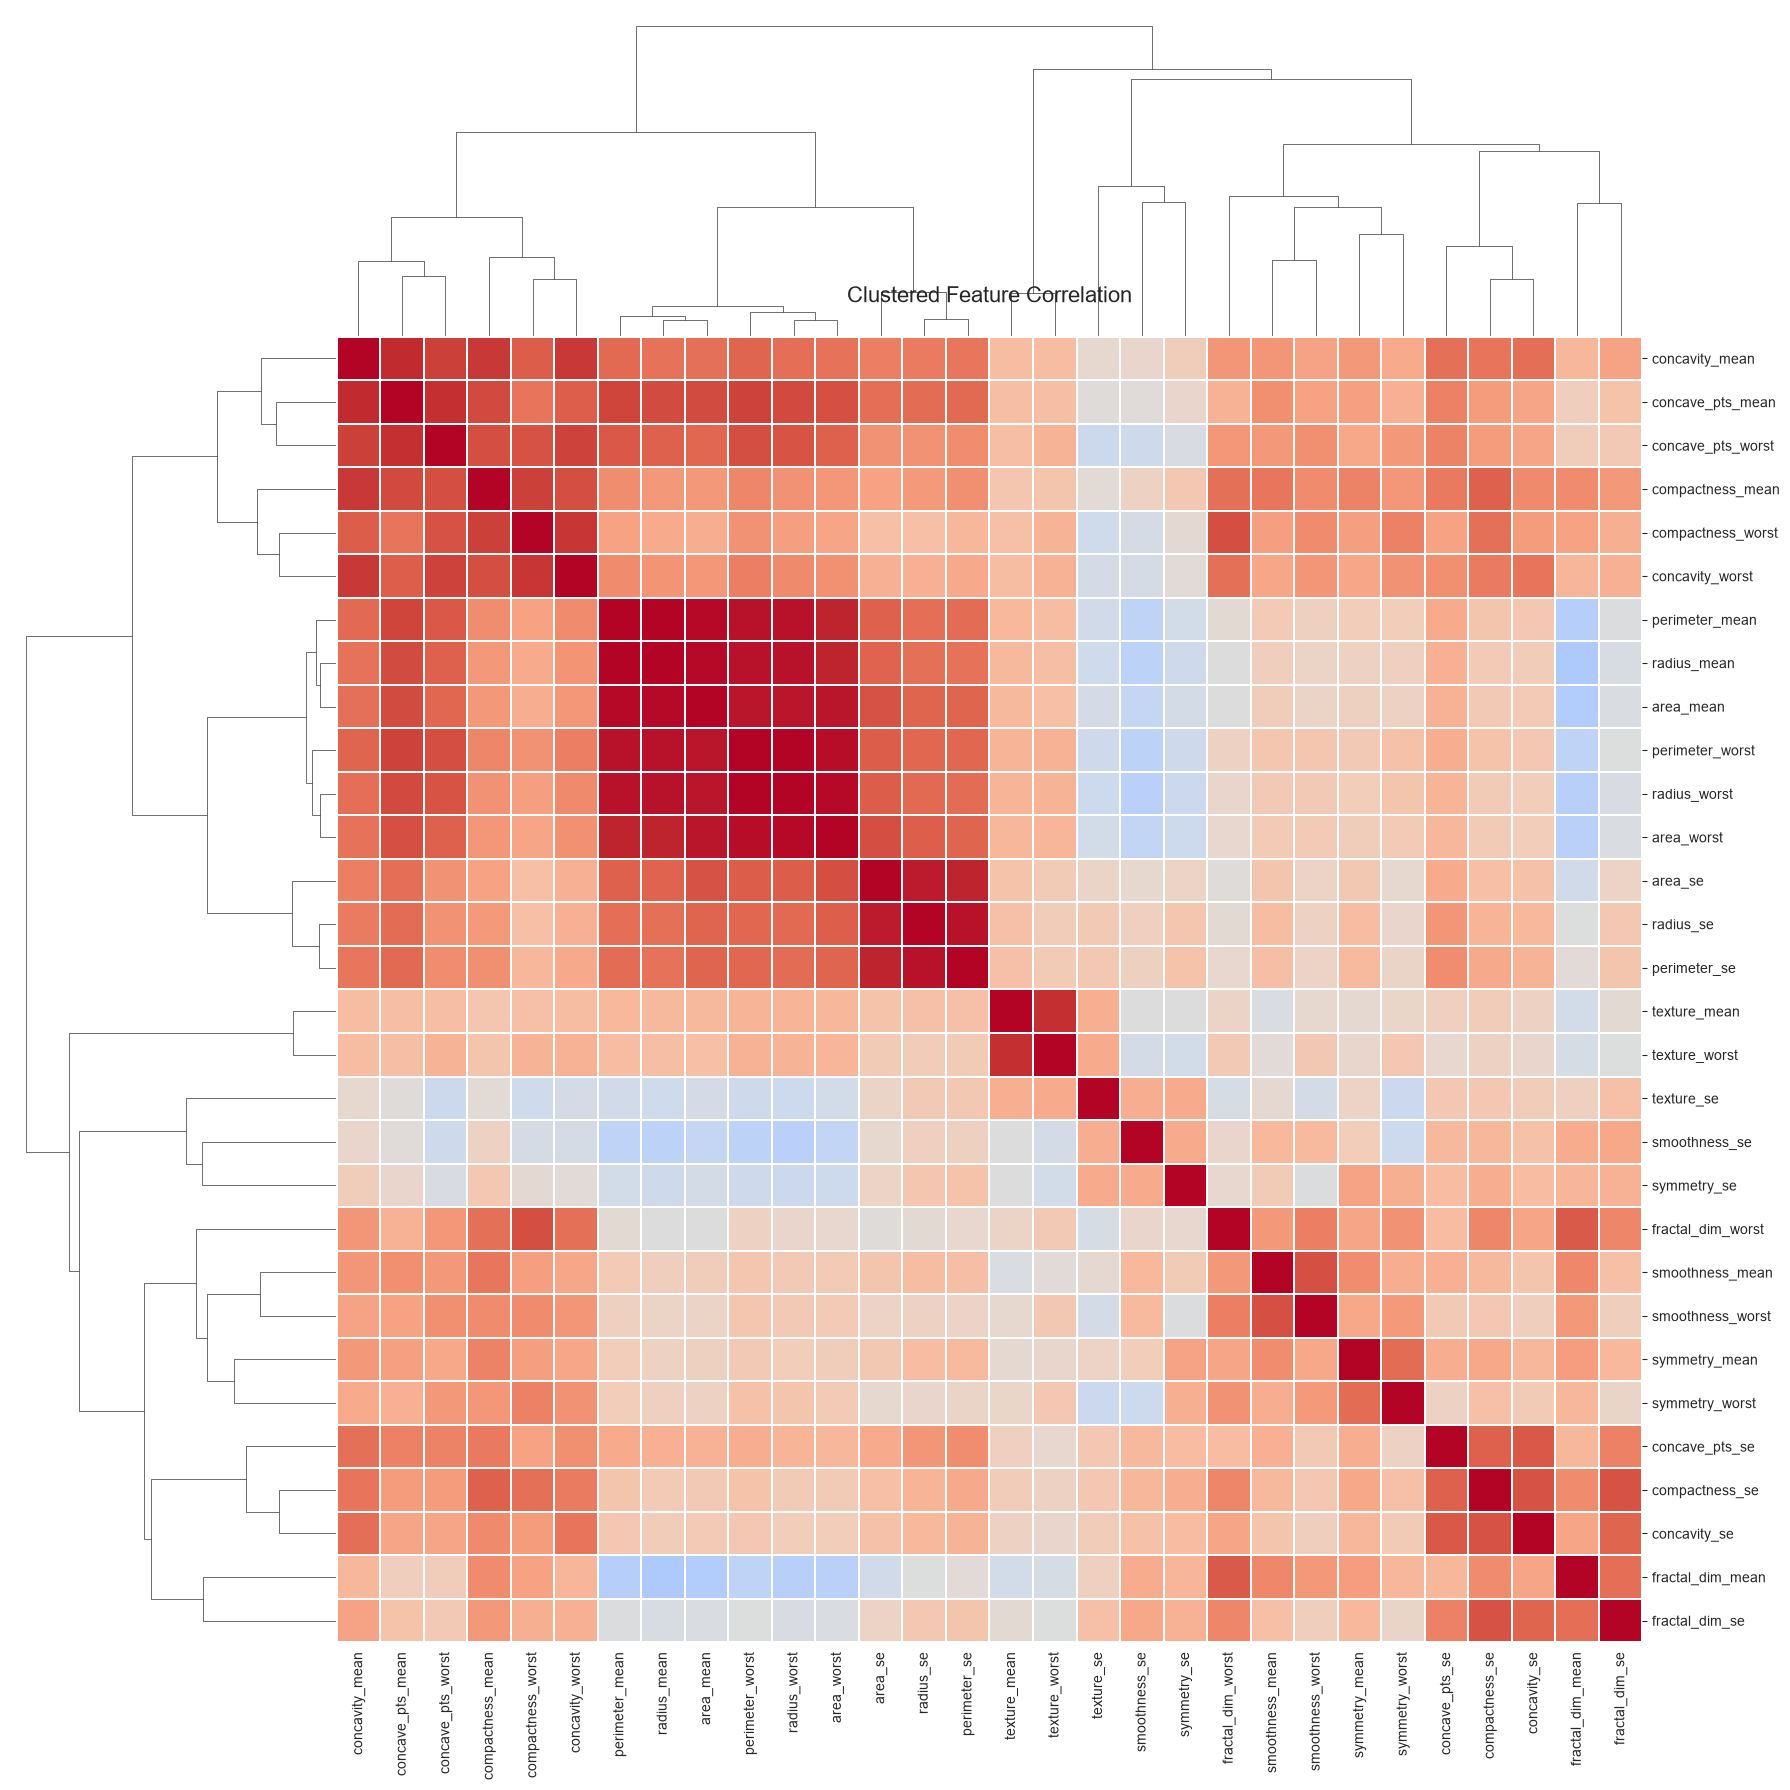

In [43]:
#cluster and reorder
g = sns.clustermap(brca[features].corr(),
                   cmap='coolwarm', center=0,
                   figsize=(18, 18),
                   linewidths=0.3,
                   cbar_pos=None)
plt.title('Clustered Feature Correlation', fontsize=16, y=1.02)
plt.savefig('../images/clustermap.png', dpi=150, bbox_inches='tight')
plt.show()

### Correlation Analysis: Findings

**Feature clustering (from clustermap):**

Three distinct feature families emerged:

1. **Size family** (9 features, |r| > 0.94): `radius_*`, `perimeter_*`, `area_*`
    essentially the same measurement in different units.

2. **Shape family** (6 features, |r| > 0.85): `concavity_*`, `concave_pts_*`,
   `compactness_*` overlapping measures of border irregularity.

3. **Texture family** (moderate internal correlation): `smoothness_*`,
   `symmetry_*`, `fractal_dim_*` weak predictors of malignancy.

**Target correlations (ranked):**

- Strongest: `concave_pts_worst`, `perimeter_worst`, `radius_worst`,
  `concave_pts_mean` — all |r| ≈ 0.75–0.79
- Weakest: `smoothness_se`, `texture_se`, `fractal_dim_mean`, `symmetry_se`
  all |r| < 0.10

**Multicollinearity warning:**

Top 5 highest |r| pairs:
- `radius_mean` - `perimeter_mean`: 0.998
- `radius_worst` - `perimeter_worst`: 0.994
- `radius_mean` - `area_mean`: 0.987
- `perimeter_mean` - `area_mean`: 0.987
- `radius_worst` - `area_worst`: 0.984

These features will be handled via L2 regularization (ridge) in the baseline
logistic regression to prevent unstable coefficient estimates.

**Modeling implication:**

Of 30 features, ~15 appear to be redundant or weak. A reduced feature set
(size + shape families, one representative each) is expected to match full-
feature performance while being more interpretable.

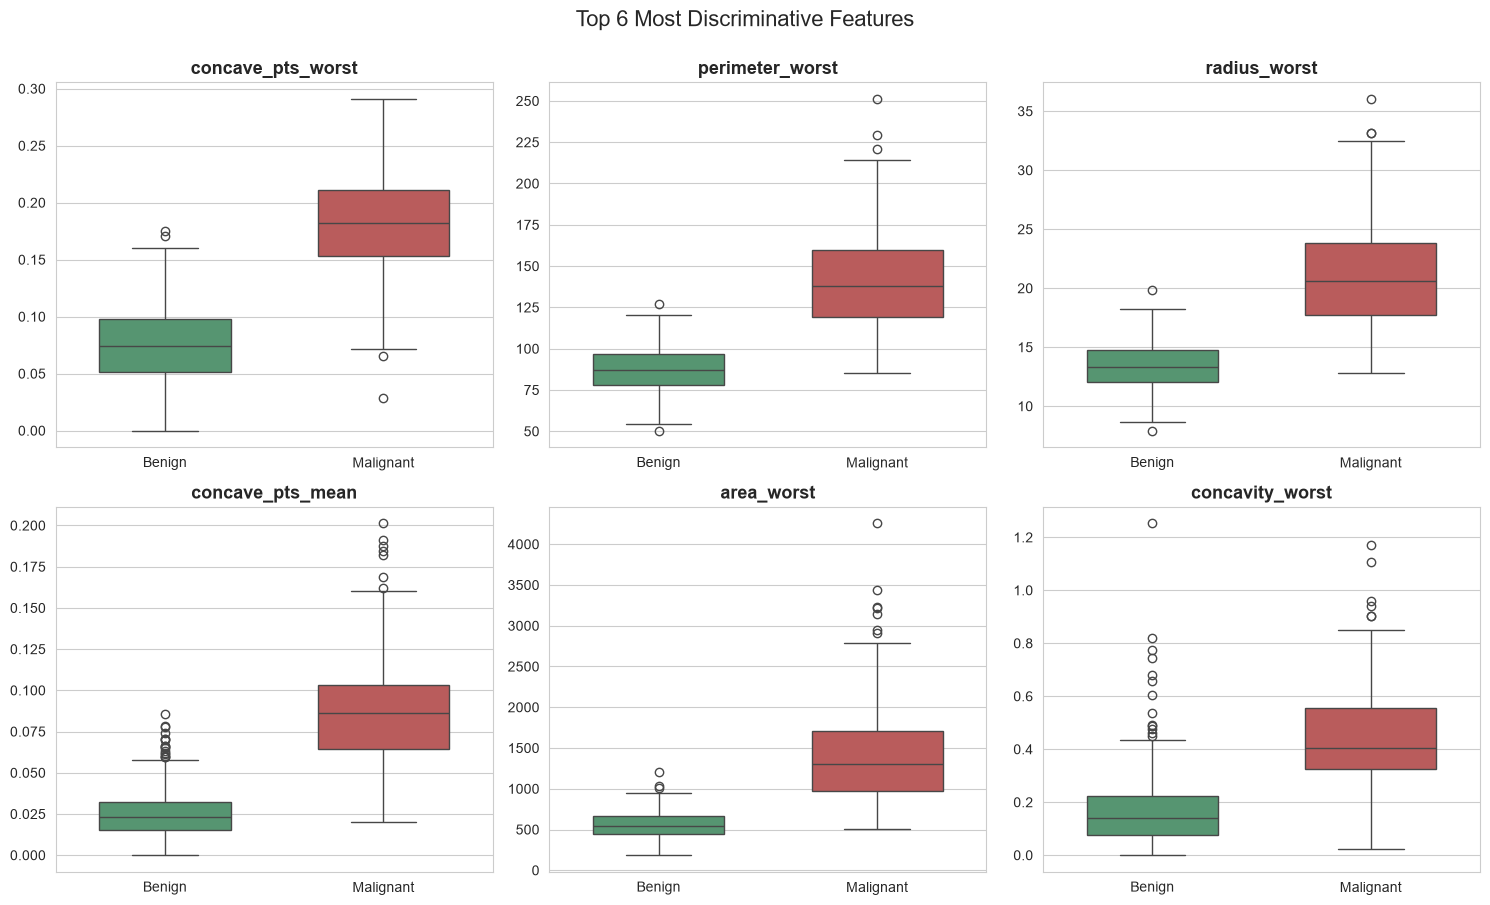

In [42]:
top_6 = ['concave_pts_worst', 'perimeter_worst', 'radius_worst',
         'concave_pts_mean', 'area_worst', 'concavity_worst']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feat in enumerate(top_6):
    sns.boxplot(data=brca, x='diagnosis_label', y=feat, ax=axes[i],
                palette={'Benign': '#4C9F70', 'Malignant': '#C94C4C'},
                hue='diagnosis_label', legend=False, width=0.6)
    axes[i].set_title(feat, fontsize=13, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

fig.suptitle('Top 6 Most Discriminative Features', fontsize=16, y=1.00)
plt.tight_layout()
plt.savefig('../images/top6_features.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpreting the Coefficients: A Multicollinearity Artifact

The largest negative coefficient in the model is `compactness_se`. Taken at
face value, this suggests "more compactness = less likely to be malignant,"
which contradicts the correlation analysis. The explanation is
**multicollinearity**: `compactness_se` is correlated with `concavity_se`,
`concave_pts_se`, and other shape features, so the model redistributes their
joint signal assigning one feature a negative weight to "correct" the
others' contributions.

L2 regularization (ridge) limits how large these opposing coefficients can
get, which is why the model remains stable and accurate despite the
correlations. This is a textbook example of why coefficient interpretation
requires care when features are not independent.

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# note: brca is ordered by class (all Benign first) so stratify is ESSENTIAL
X = brca.drop(columns=['diagnosis', 'diagnosis_label'])
y = brca['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train class balance: {y_train.value_counts(normalize=True).round(3).to_dict()}")
print(f"Test  class balance: {y_test.value_counts(normalize=True).round(3).to_dict()}")

Train: (455, 30), Test: (114, 30)
Train class balance: {0: 0.626, 1: 0.374}
Test  class balance: {0: 0.632, 1: 0.368}


In [35]:
from sklearn.linear_model import LogisticRegression


model = LogisticRegression(
    max_iter=1000,
    C=1.0,                 
    solver='lbfgs',
    random_state=42
)

model.fit(X_train_scaled, y_train)

print(f"Training accuracy: {model.score(X_train_scaled, y_train):.4f}")
print(f"Test accuracy:     {model.score(X_test_scaled, y_test):.4f}")

Training accuracy: 0.9868
Test accuracy:     0.9649


Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

ROC-AUC: 0.9960


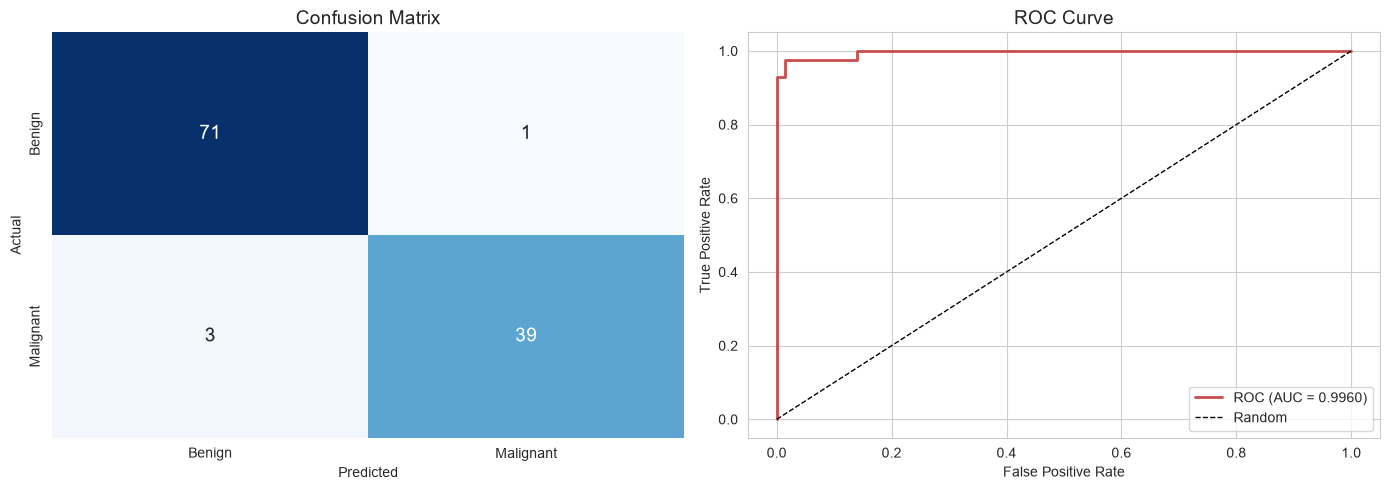

In [36]:
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]   # probability of Malignant

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Benign', 'Malignant']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")

# Confusion matrix plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'],
            ax=axes[0], annot_kws={'size': 14})
axes[0].set_title('Confusion Matrix', fontsize=14)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#C94C4C', linewidth=2, label=f'ROC (AUC = {auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontsize=14)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('../images/model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

Top 10 most influential features (by |coefficient|):
         feature  coefficient
   texture_worst     1.434093
       radius_se     1.233325
  symmetry_worst     1.061264
concave_pts_mean     0.952813
 concavity_worst     0.911406
         area_se     0.909029
  compactness_se    -0.906925
      area_worst     0.900477
    radius_worst     0.896968
  concavity_mean     0.782298


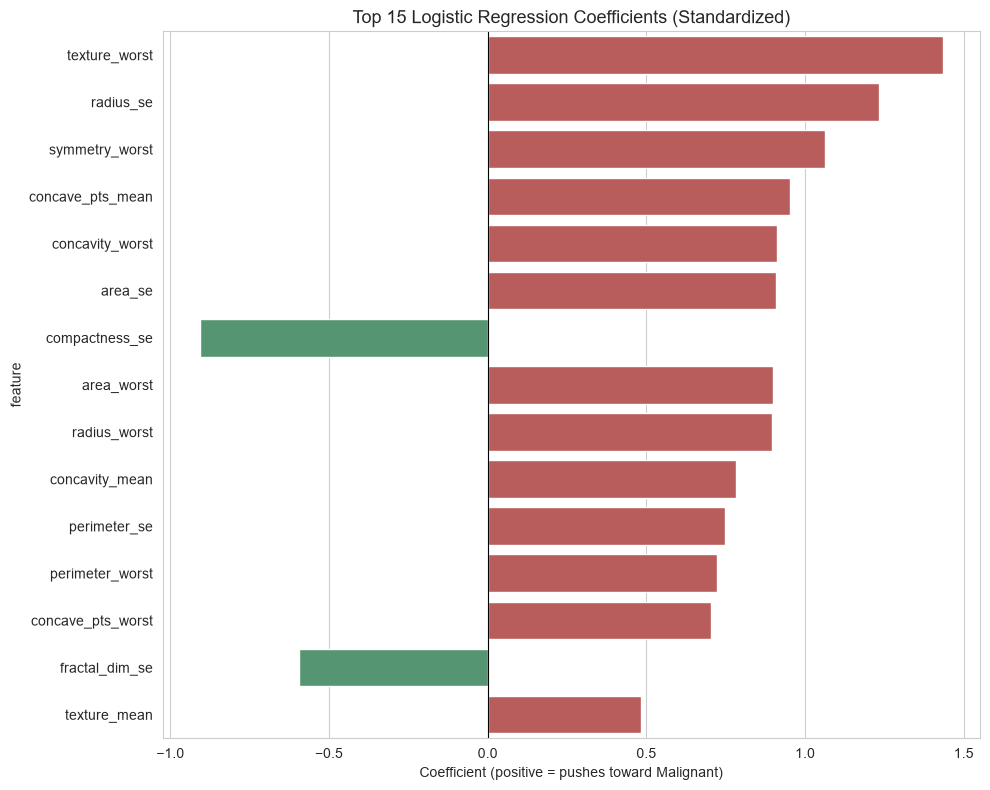

In [44]:
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print("Top 10 most influential features (by |coefficient|):")
print(coef_df.head(10).to_string(index=False))

# Plot
plt.figure(figsize=(10, 8))
top_coefs = coef_df.head(15)
colors = ['#C94C4C' if c > 0 else '#4C9F70' for c in top_coefs['coefficient']]
sns.barplot(x='coefficient', y='feature', data=top_coefs,
            hue='feature', palette=colors, legend=False)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 Logistic Regression Coefficients (Standardized)', fontsize=13)
plt.xlabel('Coefficient (positive = pushes toward Malignant)')
plt.tight_layout()
plt.savefig('../images/coefficients.png', dpi=150, bbox_inches='tight')
plt.show()